App Value Proposition Statement: 
For chemical engineering students/professionals who must plot XY diagrams in order to properly analyze the behavior of a binary mixture, my app will plot the XY diagram requiring few user inputs. Unlike spreadsheet calculations that require gathering values and inputting equations, my app will only require knowledge of models and basic specifications. Alternatively, unlike heavier software such as ASPEN Plus, my app will minimize software loading and calculation times, resulting in faster outputs.  

Description & Engineering Basis: 
- Function 1: Completes analysis of a binary mixture that consist of user specified components, methods, and pressure
- Function 2: Plots the XY graph of the binary system, and identifies/outputs if the mixture consists of an azeotrope and the composition that the azeotrope crosses at
- Basis: Methods of Ideal and NRTL
- Equations: Vapor-Liquid Equation, Antoine Equation, NRTL Activity-Coeffecient Model, and Bubble Point Equation

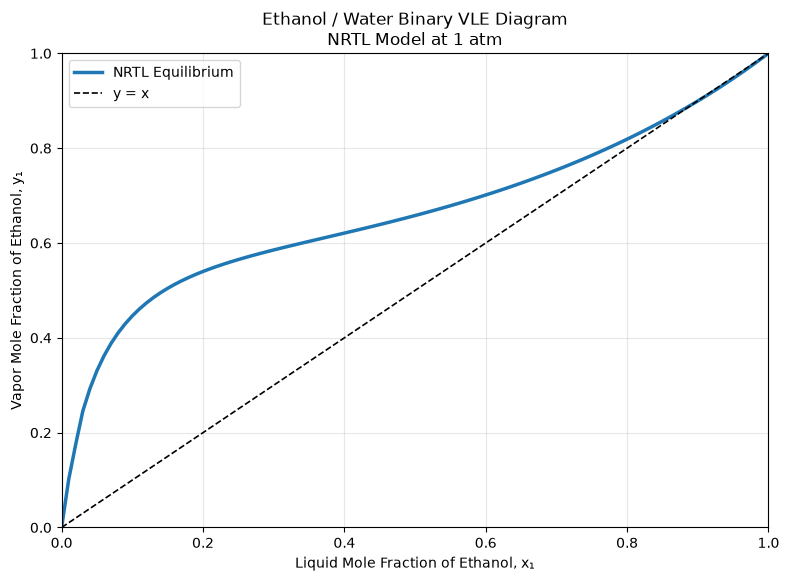

In [6]:
# ======================================================================
# BINARY VAPOR-LIQUID EQUILIBRIUM (VLE) GUI
#
# Components:
#   - Methanol
#   - Ethanol
#   - Water
#
# Models:
#   - Ideal
#   - NRTL
#
# User Inputs:
#   - Component 1
#   - Component 2
#   - Thermodynamic Model
#   - Pressure
#   - Pressure Units
#
# Output:
#   - Binary x-y equilibrium diagram
#   - Calculated bubble-temperature range
# ======================================================================


# ======================================================================
# 1. IMPORT PACKAGES
# ======================================================================

import tkinter as tk
from tkinter import ttk, messagebox

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from scipy.optimize import brentq


# ======================================================================
# 2. PURE-COMPONENT ANTOINE DATA
# ======================================================================
#
# Antoine equation:
#
# log10(Psat) = A - B/(T + C)
#
# T    = Kelvin
# Psat = bar
#
# ======================================================================

COMPONENTS = {

    "Methanol": {
        "antoine": [
            (288.10, 356.83, 5.20409, 1581.341, -33.50),
            (353.50, 512.63, 5.15853, 1569.613, -34.846)
        ]
    },

    "Ethanol": {
        "antoine": [
            (273.00, 351.70, 5.37229, 1670.409, -40.191),
            (292.77, 366.63, 5.24677, 1598.673, -46.424),
            (364.80, 513.91, 4.92531, 1432.526, -61.819)
        ]
    },

    "Water": {
        "antoine": [
            (273.00, 303.00, 5.40221, 1838.675, -31.737),
            (304.00, 333.00, 5.20389, 1733.926, -39.485),
            (334.00, 363.00, 5.07680, 1659.793, -45.854),
            (344.00, 373.00, 5.08354, 1663.125, -45.622),
            (379.00, 573.00, 3.55959, 643.748, -198.043)
        ]
    }
}


# ======================================================================
# 3. NRTL BINARY INTERACTION PARAMETERS
# ======================================================================
#
# These are the Aspen parameters entered earlier.
#
# Aspen temperature-dependent NRTL form:
#
# tau_ij = Aij + Bij/T
#
# Gij = exp(-alpha_ij * tau_ij)
#
# alpha = 0.3
#
# T is in Kelvin.
#
# ======================================================================

NRTL_PARAMETERS = {

    ("Ethanol", "Water"): {
        "A12": -0.8009,
        "A21": 3.4578,
        "B12": 246.18,
        "B21": -586.081,
        "alpha": 0.3
    },

    ("Ethanol", "Methanol"): {
        "A12": -2.3127,
        "A21": 4.7119,
        "B12": 483.844,
        "B21": -1162.29,
        "alpha": 0.3
    },

    ("Water", "Methanol"): {
        "A12": 2.7322,
        "A21": -0.693,
        "B12": -617.269,
        "B21": 172.987,
        "alpha": 0.3
    }
}


# ======================================================================
# 4. PRESSURE CONVERSION
# ======================================================================

def pressure_to_bar(P, unit):

    if unit == "bar":
        return P

    elif unit == "atm":
        return P * 1.01325

    elif unit == "kPa":
        return P / 100.0

    elif unit == "mmHg":
        return P / 750.062

    else:
        raise ValueError("Unknown pressure unit.")


# ======================================================================
# 5. SATURATION PRESSURE
# ======================================================================

def psat(component, T):

    """
    Calculates saturation pressure in bar.

    Parameters
    ----------
    component : string
        Methanol, Ethanol, or Water

    T : float
        Temperature in Kelvin
    """

    ranges = COMPONENTS[component]["antoine"]

    # Find an Antoine range containing the temperature

    valid_ranges = [
        row for row in ranges
        if row[0] <= T <= row[1]
    ]

    if valid_ranges:

        Tmin, Tmax, A, B, C = valid_ranges[0]

    else:

        # If T lies slightly outside the tabulated ranges,
        # use the nearest correlation.

        Tmin, Tmax, A, B, C = min(
            ranges,
            key=lambda row:
            min(
                abs(T - row[0]),
                abs(T - row[1])
            )
        )

    P_sat = 10 ** (
        A - B/(T + C)
    )

    return P_sat


# ======================================================================
# 6. GET NRTL PARAMETERS
# ======================================================================

def get_nrtl_parameters(comp1, comp2, T):

    pair = (comp1, comp2)

    reverse_pair = (comp2, comp1)

    # --------------------------------------------------------------
    # Pair stored in normal direction
    # --------------------------------------------------------------

    if pair in NRTL_PARAMETERS:

        p = NRTL_PARAMETERS[pair]

        A12 = p["A12"]
        A21 = p["A21"]

        B12 = p["B12"]
        B21 = p["B21"]

        alpha = p["alpha"]


    # --------------------------------------------------------------
    # Pair stored in reverse direction
    # --------------------------------------------------------------

    elif reverse_pair in NRTL_PARAMETERS:

        p = NRTL_PARAMETERS[reverse_pair]

        # Reverse 1 -> 2 and 2 -> 1

        A12 = p["A21"]
        A21 = p["A12"]

        B12 = p["B21"]
        B21 = p["B12"]

        alpha = p["alpha"]


    else:

        raise ValueError(
            f"No NRTL parameters are available "
            f"for {comp1} / {comp2}."
        )


    # --------------------------------------------------------------
    # Temperature-dependent tau values
    # --------------------------------------------------------------

    tau12 = A12 + B12/T

    tau21 = A21 + B21/T


    return tau12, tau21, alpha


# ======================================================================
# 7. NRTL ACTIVITY COEFFICIENTS
# ======================================================================

def nrtl_gamma(x1, comp1, comp2, T):

    """
    Calculates activity coefficients gamma1 and gamma2
    for a binary mixture using NRTL.
    """

    x2 = 1.0 - x1


    # --------------------------------------------------------------
    # Get NRTL parameters
    # --------------------------------------------------------------

    tau12, tau21, alpha = get_nrtl_parameters(
        comp1,
        comp2,
        T
    )


    # --------------------------------------------------------------
    # Calculate G values
    # --------------------------------------------------------------

    G12 = np.exp(
        -alpha * tau12
    )

    G21 = np.exp(
        -alpha * tau21
    )


    # --------------------------------------------------------------
    # Denominators
    # --------------------------------------------------------------

    denominator1 = (
        x1 + x2*G21
    )

    denominator2 = (
        x2 + x1*G12
    )


    # --------------------------------------------------------------
    # Component 1 activity coefficient
    # --------------------------------------------------------------

    ln_gamma1 = (

        x2**2

        *

        (
            tau21
            *
            (G21/denominator1)**2

            +

            tau12
            *
            G12
            /
            denominator2**2
        )
    )


    # --------------------------------------------------------------
    # Component 2 activity coefficient
    # --------------------------------------------------------------

    ln_gamma2 = (

        x1**2

        *

        (
            tau12
            *
            (G12/denominator2)**2

            +

            tau21
            *
            G21
            /
            denominator1**2
        )
    )


    gamma1 = np.exp(
        ln_gamma1
    )

    gamma2 = np.exp(
        ln_gamma2
    )


    return gamma1, gamma2


# ======================================================================
# 8. BUBBLE-POINT EQUATION
# ======================================================================

def bubble_equation(
        T,
        x1,
        comp1,
        comp2,
        P,
        model):

    """
    Bubble-point equation:

    P = x1*gamma1*P1sat
        + x2*gamma2*P2sat
    """

    x2 = 1.0 - x1


    # --------------------------------------------------------------
    # Saturation pressures
    # --------------------------------------------------------------

    P1sat = psat(
        comp1,
        T
    )

    P2sat = psat(
        comp2,
        T
    )


    # --------------------------------------------------------------
    # Ideal model
    # --------------------------------------------------------------

    if model == "Ideal":

        gamma1 = 1.0
        gamma2 = 1.0


    # --------------------------------------------------------------
    # NRTL model
    # --------------------------------------------------------------

    elif model == "NRTL":

        gamma1, gamma2 = nrtl_gamma(
            x1,
            comp1,
            comp2,
            T
        )


    else:

        raise ValueError(
            "Unknown thermodynamic model."
        )


    # --------------------------------------------------------------
    # Modified Raoult's Law
    # --------------------------------------------------------------

    P_calculated = (

        x1
        *
        gamma1
        *
        P1sat

        +

        x2
        *
        gamma2
        *
        P2sat
    )


    return P_calculated - P


# ======================================================================
# 9. SOLVE BUBBLE-POINT TEMPERATURE
# ======================================================================

def solve_bubble_temperature(
        x1,
        comp1,
        comp2,
        P,
        model):

    """
    Searches for a valid bubble-point temperature.

    A temperature scan is used first so that brentq
    receives a valid bracket.
    """

    # Search from approximately -3 C to 227 C

    T_scan = np.linspace(
        270.0,
        500.0,
        250
    )


    previous_T = None
    previous_f = None


    for T in T_scan:

        try:

            f = bubble_equation(
                T,
                x1,
                comp1,
                comp2,
                P,
                model
            )

        except Exception:

            continue


        if not np.isfinite(f):

            continue


        if previous_f is not None:

            # Check for sign change

            if previous_f * f < 0:

                T_bubble = brentq(

                    bubble_equation,

                    previous_T,
                    T,

                    args=(
                        x1,
                        comp1,
                        comp2,
                        P,
                        model
                    )
                )

                return T_bubble


        # Exact solution

        if abs(f) < 1e-10:

            return T


        previous_T = T
        previous_f = f


    raise ValueError(
        "No bubble-point temperature could be found."
    )


# ======================================================================
# 10. GENERATE x-y EQUILIBRIUM DATA
# ======================================================================

def generate_vle(
        comp1,
        comp2,
        P,
        model):

    """
    Generates binary x-y equilibrium data.
    """

    # Include pure-component endpoints

    x_values = np.linspace(
        0.0,
        1.0,
        101
    )


    y_values = []

    temperature_values = []


    # --------------------------------------------------------------
    # Calculate equilibrium at every liquid composition
    # --------------------------------------------------------------

    for x1 in x_values:

        try:

            # Bubble-point temperature

            T = solve_bubble_temperature(
                x1,
                comp1,
                comp2,
                P,
                model
            )


            # Saturation pressures

            P1sat = psat(
                comp1,
                T
            )

            P2sat = psat(
                comp2,
                T
            )


            # ------------------------------------------------------
            # Activity coefficients
            # ------------------------------------------------------

            if model == "Ideal":

                gamma1 = 1.0
                gamma2 = 1.0


            elif model == "NRTL":

                gamma1, gamma2 = nrtl_gamma(
                    x1,
                    comp1,
                    comp2,
                    T
                )


            # ------------------------------------------------------
            # Vapor compositions
            # ------------------------------------------------------

            x2 = 1.0 - x1


            y1 = (
                x1
                *
                gamma1
                *
                P1sat
                /
                P
            )


            y2 = (
                x2
                *
                gamma2
                *
                P2sat
                /
                P
            )


            # Normalize to eliminate small numerical errors

            total_y = y1 + y2


            if total_y <= 0:

                raise ValueError(
                    "Invalid vapor composition."
                )


            y1 = y1 / total_y


            # Prevent tiny numerical excursions

            y1 = np.clip(
                y1,
                0.0,
                1.0
            )


            y_values.append(
                y1
            )


            temperature_values.append(
                T
            )


        except Exception:

            # Failed points are skipped instead of
            # crashing the entire program.

            y_values.append(
                np.nan
            )

            temperature_values.append(
                np.nan
            )


    return (
        x_values,
        np.array(y_values),
        np.array(temperature_values)
    )


# ======================================================================
# 11. GUI APPLICATION
# ======================================================================

class VLEApp:


    def __init__(self, root):

        self.root = root


        # --------------------------------------------------------------
        # Main window
        # --------------------------------------------------------------

        self.root.title(
            "Binary VLE Analysis Tool"
        )


        self.root.geometry(
            "1200x720"
        )


        self.root.minsize(
            1000,
            650
        )


        # --------------------------------------------------------------
        # Main title
        # --------------------------------------------------------------

        title = tk.Label(

            root,

            text=
            "Binary Vapor-Liquid Equilibrium Analysis Tool",

            font=(
                "Arial",
                18,
                "bold"
            )
        )


        title.pack(
            pady=(12, 3)
        )


        subtitle = tk.Label(

            root,

            text=
            "Methanol • Ethanol • Water",

            font=(
                "Arial",
                10
            )
        )


        subtitle.pack(
            pady=(0, 8)
        )


        # --------------------------------------------------------------
        # Main container
        # --------------------------------------------------------------

        main_frame = tk.Frame(
            root
        )


        main_frame.pack(
            fill="both",
            expand=True
        )


        # ==============================================================
        # LEFT SIDE - USER INPUTS
        # ==============================================================

        input_frame = tk.LabelFrame(

            main_frame,

            text="Engineering Inputs",

            padx=20,
            pady=20
        )


        input_frame.pack(

            side="left",

            fill="y",

            padx=10,
            pady=10
        )


        # --------------------------------------------------------------
        # Component 1
        # --------------------------------------------------------------

        tk.Label(

            input_frame,

            text="Component 1:"

        ).grid(

            row=0,
            column=0,

            sticky="w",

            pady=8
        )


        self.comp1 = ttk.Combobox(

            input_frame,

            values=[
                "Methanol",
                "Ethanol",
                "Water"
            ],

            state="readonly",

            width=18
        )


        self.comp1.set(
            "Ethanol"
        )


        self.comp1.grid(

            row=0,
            column=1,

            padx=8
        )


        # --------------------------------------------------------------
        # Component 2
        # --------------------------------------------------------------

        tk.Label(

            input_frame,

            text="Component 2:"

        ).grid(

            row=1,
            column=0,

            sticky="w",

            pady=8
        )


        self.comp2 = ttk.Combobox(

            input_frame,

            values=[
                "Methanol",
                "Ethanol",
                "Water"
            ],

            state="readonly",

            width=18
        )


        self.comp2.set(
            "Water"
        )


        self.comp2.grid(

            row=1,
            column=1,

            padx=8
        )


        # --------------------------------------------------------------
        # Thermodynamic model
        # --------------------------------------------------------------

        tk.Label(

            input_frame,

            text="Thermodynamic Model:"

        ).grid(

            row=2,
            column=0,

            sticky="w",

            pady=8
        )


        self.model = ttk.Combobox(

            input_frame,

            values=[
                "Ideal",
                "NRTL"
            ],

            state="readonly",

            width=18
        )


        self.model.set(
            "NRTL"
        )


        self.model.grid(

            row=2,
            column=1,

            padx=8
        )


        # --------------------------------------------------------------
        # Pressure
        # --------------------------------------------------------------

        tk.Label(

            input_frame,

            text="System Pressure:"

        ).grid(

            row=3,
            column=0,

            sticky="w",

            pady=8
        )


        self.pressure_entry = tk.Entry(

            input_frame,

            width=21
        )


        self.pressure_entry.insert(
            0,
            "1.0"
        )


        self.pressure_entry.grid(

            row=3,
            column=1,

            padx=8
        )


        # --------------------------------------------------------------
        # Pressure units
        # --------------------------------------------------------------

        tk.Label(

            input_frame,

            text="Pressure Units:"

        ).grid(

            row=4,
            column=0,

            sticky="w",

            pady=8
        )


        self.pressure_units = ttk.Combobox(

            input_frame,

            values=[
                "atm",
                "bar",
                "kPa",
                "mmHg"
            ],

            state="readonly",

            width=18
        )


        self.pressure_units.set(
            "atm"
        )


        self.pressure_units.grid(

            row=4,
            column=1,

            padx=8
        )


        # --------------------------------------------------------------
        # Separator
        # --------------------------------------------------------------

        ttk.Separator(

            input_frame,

            orient="horizontal"

        ).grid(

            row=5,
            column=0,

            columnspan=2,

            sticky="ew",

            pady=15
        )


        # --------------------------------------------------------------
        # Buttons
        # --------------------------------------------------------------

        button_frame = tk.Frame(
            input_frame
        )


        button_frame.grid(

            row=6,
            column=0,

            columnspan=2,

            pady=10
        )


        # RUN

        run_button = tk.Button(

            button_frame,

            text="RUN ANALYSIS",

            command=
            self.run_analysis,

            width=15,
            height=2
        )


        run_button.pack(

            side="left",

            padx=4
        )


        # CLEAR

        clear_button = tk.Button(

            button_frame,

            text="CLEAR",

            command=
            self.clear_plot,

            width=10,
            height=2
        )


        clear_button.pack(

            side="left",

            padx=4
        )


        # EXIT

        exit_button = tk.Button(

            button_frame,

            text="EXIT",

            command=
            self.root.destroy,

            width=10,
            height=2
        )


        exit_button.pack(

            side="left",

            padx=4
        )


        # --------------------------------------------------------------
        # Results box
        # --------------------------------------------------------------

        results_frame = tk.LabelFrame(

            input_frame,

            text="Analysis Results",

            padx=10,
            pady=10
        )


        results_frame.grid(

            row=7,
            column=0,

            columnspan=2,

            sticky="ew",

            pady=15
        )


        self.results_label = tk.Label(

            results_frame,

            text=
            "Select the components, model, and pressure,\n"
            "then click RUN ANALYSIS.",

            justify="left",

            anchor="w",

            wraplength=330
        )


        self.results_label.pack(
            fill="x"
        )


        # ==============================================================
        # RIGHT SIDE - GRAPH
        # ==============================================================

        plot_frame = tk.LabelFrame(

            main_frame,

            text="Binary x-y Equilibrium Diagram",

            padx=5,
            pady=5
        )


        plot_frame.pack(

            side="right",

            fill="both",

            expand=True,

            padx=10,
            pady=10
        )


        # --------------------------------------------------------------
        # Create matplotlib figure
        # --------------------------------------------------------------

        self.figure, self.ax = plt.subplots(

            figsize=(
                7,
                6
            )
        )


        # --------------------------------------------------------------
        # Put matplotlib inside Tkinter
        # --------------------------------------------------------------

        self.canvas = FigureCanvasTkAgg(

            self.figure,

            master=
            plot_frame
        )


        self.canvas.get_tk_widget().pack(

            fill="both",

            expand=True
        )


        # --------------------------------------------------------------
        # Initial blank graph
        # --------------------------------------------------------------

        self.create_blank_plot()


    # ==================================================================
    # 12. CREATE BLANK GRAPH
    # ==================================================================

    def create_blank_plot(self):

        self.ax.clear()


        # 45-degree reference line

        self.ax.plot(

            [0, 1],

            [0, 1],

            "k--",

            linewidth=1.2,

            label="y = x"
        )


        self.ax.set_xlim(
            0,
            1
        )


        self.ax.set_ylim(
            0,
            1
        )


        self.ax.set_xlabel(
            "Liquid Mole Fraction, x₁"
        )


        self.ax.set_ylabel(
            "Vapor Mole Fraction, y₁"
        )


        self.ax.set_title(
            "Binary x-y Equilibrium Diagram"
        )


        self.ax.grid(
            True,
            alpha=0.3
        )


        self.ax.legend(
            loc="best"
        )


        self.figure.tight_layout()


        self.canvas.draw()


    # ==================================================================
    # 13. CLEAR BUTTON
    # ==================================================================

    def clear_plot(self):

        self.create_blank_plot()


        self.results_label.config(

            text=
            "Select the components, model, and pressure,\n"
            "then click RUN ANALYSIS."
        )


    # ==================================================================
    # 14. RUN ANALYSIS BUTTON
    # ==================================================================

    def run_analysis(self):

        try:

            # ----------------------------------------------------------
            # Read component selections
            # ----------------------------------------------------------

            comp1 = self.comp1.get()

            comp2 = self.comp2.get()


            # Components cannot be identical

            if comp1 == comp2:

                raise ValueError(
                    "Please select two different components."
                )


            # ----------------------------------------------------------
            # Read thermodynamic model
            # ----------------------------------------------------------

            selected_model = self.model.get()


            # ----------------------------------------------------------
            # Read pressure
            # ----------------------------------------------------------

            pressure_input = float(
                self.pressure_entry.get()
            )


            if pressure_input <= 0:

                raise ValueError(
                    "Pressure must be greater than zero."
                )


            pressure_unit = (
                self.pressure_units.get()
            )


            # Convert pressure to bar internally

            P_bar = pressure_to_bar(
                pressure_input,
                pressure_unit
            )


            # ----------------------------------------------------------
            # Generate equilibrium data
            # ----------------------------------------------------------

            xeq, yeq, Teq = generate_vle(

                comp1,
                comp2,
                P_bar,
                selected_model
            )


            # ----------------------------------------------------------
            # Find valid points
            # ----------------------------------------------------------

            valid = (

                np.isfinite(xeq)

                &

                np.isfinite(yeq)
            )


            number_valid = np.sum(
                valid
            )


            if number_valid < 10:

                raise ValueError(

                    "The program could not calculate enough "
                    "valid equilibrium points at the selected "
                    "conditions."
                )


            # ----------------------------------------------------------
            # Clear old graph
            # ----------------------------------------------------------

            self.ax.clear()


            # ----------------------------------------------------------
            # Plot equilibrium curve
            # ----------------------------------------------------------

            self.ax.plot(

                xeq[valid],

                yeq[valid],

                linewidth=2.5,

                label=
                f"{selected_model} Equilibrium"
            )


            # ----------------------------------------------------------
            # Plot 45-degree line
            # ----------------------------------------------------------

            self.ax.plot(

                [0, 1],

                [0, 1],

                "k--",

                linewidth=1.2,

                label="y = x"
            )


            # ----------------------------------------------------------
            # Determine temperature range
            # ----------------------------------------------------------

            valid_T = Teq[
                np.isfinite(Teq)
            ]


            if len(valid_T) > 0:

                Tmin_K = np.min(
                    valid_T
                )

                Tmax_K = np.max(
                    valid_T
                )


                Tmin_C = (
                    Tmin_K - 273.15
                )

                Tmax_C = (
                    Tmax_K - 273.15
                )


                temperature_text = (

                    f"{Tmin_C:.2f} to "
                    f"{Tmax_C:.2f} °C"
                )


            else:

                temperature_text = (
                    "Not available"
                )


            # ----------------------------------------------------------
            # Check for approximate azeotrope
            # ----------------------------------------------------------

            differences = (
                yeq[valid]
                -
                xeq[valid]
            )


            azeotrope_text = (
                "No interior crossing detected"
            )


            valid_x = xeq[valid]
            valid_y = yeq[valid]


            for i in range(
                len(valid_x)-1
            ):

                # Ignore pure-component endpoints

                if (
                    valid_x[i] < 0.02
                    or
                    valid_x[i] > 0.98
                ):

                    continue


                difference1 = (
                    valid_y[i]
                    -
                    valid_x[i]
                )


                difference2 = (
                    valid_y[i+1]
                    -
                    valid_x[i+1]
                )


                if (
                    difference1
                    *
                    difference2
                    < 0
                ):

                    x_azeotrope = (
                        valid_x[i]
                        +
                        valid_x[i+1]
                    ) / 2


                    azeotrope_text = (

                        "Possible azeotrope near "
                        f"x₁ ≈ {x_azeotrope:.3f}"
                    )


                    break


            # ----------------------------------------------------------
            # Results text
            # ----------------------------------------------------------

            results_text = (

                f"Mixture: {comp1} / {comp2}"

                f"\nModel: {selected_model}"

                f"\nPressure: "
                f"{pressure_input:g} "
                f"{pressure_unit}"

                f"\nValid Points: "
                f"{number_valid}"

                f"\nBubble Temperature Range: "
                f"{temperature_text}"

                f"\nAzeotrope Check: "
                f"{azeotrope_text}"
            )


            self.results_label.config(
                text=results_text
            )


            # ----------------------------------------------------------
            # Graph labels
            # ----------------------------------------------------------

            self.ax.set_xlim(
                0,
                1
            )


            self.ax.set_ylim(
                0,
                1
            )


            self.ax.set_xlabel(

                f"Liquid Mole Fraction of "
                f"{comp1}, x₁"
            )


            self.ax.set_ylabel(

                f"Vapor Mole Fraction of "
                f"{comp1}, y₁"
            )


            self.ax.set_title(

                f"{comp1} / {comp2} Binary VLE Diagram\n"

                f"{selected_model} Model at "
                f"{pressure_input:g} "
                f"{pressure_unit}"
            )


            self.ax.grid(
                True,
                alpha=0.3
            )


            self.ax.legend(
                loc="best"
            )


            self.figure.tight_layout()


            # ----------------------------------------------------------
            # Update GUI graph
            # ----------------------------------------------------------

            self.canvas.draw()


        # ==============================================================
        # INPUT / CALCULATION ERROR
        # ==============================================================

        except ValueError as error:

            messagebox.showerror(

                "Input / Calculation Error",

                str(error)
            )


        # ==============================================================
        # OTHER ERROR
        # ==============================================================

        except Exception as error:

            messagebox.showerror(

                "Unexpected Error",

                "The analysis could not be completed.\n\n"

                f"Details:\n{error}"
            )


# ======================================================================
# 15. START APPLICATION
# ======================================================================

root = tk.Tk()

app = VLEApp(root)

root.mainloop()

AI Prompting Log: 

Prompt #1: 
help me create a gui in jnotebook that will plot an xy diagram for a binary mixture, allowing user inputs of temperature, units of temperature, model type (from NRTL, Ideal, and Peng-robinson), and the elements. if possible allow a button that would allow the user to input distillate composition and bottoms composition, and then plot the ideal number of stages under CMO assumption using mccabe-thiel. have a button for run analysis and exit as well

Prompt #2: 
would it be easier to only allow the selection of elements amongst, ethanol, water, and methanol for now? to allow for selection of NRTL, peng-robinson, and ideal?

Prompt #3: 
attached a screenshot of NRTL Parameters and equations utilizing ASPEN's databases

Prompt #4: 
okay include everything discussed in one final, clean code to input into jnotebook 

Prompt #5: 
Attached a screenshot of the code error that the stage calculation reached a pinch. 

Prompt #6: 
okay, can we just take out the whole stage section, create the code for just the selection of elements, model, and pressure.

prompt #7: 
the peng-robinson crashed the program

prompt #8: 
after the changes, it still crashed, should i delete the peng-robinson section?